# iシェアーズ S&P 500 米国株 ETF (1655) 日足

In [1]:
import sys

path_up = ".."
if not path_up in sys.path:
    sys.path.append(path_up)

In [2]:
import datetime

import matplotlib.font_manager as fm
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import mplfinance as mpf
import numpy as np
import pandas as pd
import yfinance as yf

In [3]:
symbol1 = "1655.T"
yticker1 = yf.Ticker(symbol1)
df0 = yticker1.history(period="3y", interval="1d")
df1 = yticker1.history(period="9mo", interval="1d")
df1

,Open,High,Low,Close,Volume,Dividends,Stock Splits,Capital Gains
Date,,,,,,,,
2026-02-25 00:00:00+09:00,769.908401,770.804881,768.214969,768.812622,1863090,0.0,0.0,0.0
2026-02-26 00:00:00+09:00,776.383217,777.180109,773.892894,775.984741,2305120,0.0,0.0,0.0
2026-02-27 00:00:00+09:00,769.011823,770.107541,767.318391,769.509888,1384700,0.0,0.0,0.0
2026-03-02 00:00:00+09:00,764.130808,767.716910,762.337787,765.923889,3547060,0.0,0.0,0.0
2026-03-03 00:00:00+09:00,774.092060,775.088189,768.712998,769.808716,3182870,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...
2026-11-18 00:00:00+09:00,851.000000,851.599976,843.900024,846.099976,1315330,0.0,0.0,0.0
2026-11-19 00:00:00+09:00,846.299988,849.900024,844.299988,849.900024,2385330,0.0,0.0,0.0
2026-11-20 00:00:00+09:00,827.200012,828.400024,819.000000,820.599976,4122640,0.0,0.0,0.0


In [4]:
def plot_month(symbol, yticker, df0, df1):
    FONT_PATH = "../fonts/RictyDiminished-Regular.ttf"
    fm.fontManager.addfont(FONT_PATH)
    
    # FontPropertiesオブジェクト生成（名前の取得のため）
    font_prop = fm.FontProperties(fname=FONT_PATH)
    font_prop.get_name()
    
    plt.rcParams["font.family"] = font_prop.get_name()
    
    fig, ax = plt.subplots(figsize=(8, 4))

    mm100 = df0["Close"].rolling(100).median()
    mm200 = df0["Close"].rolling(200).median()
    mm300 = df0["Close"].rolling(300).median()
    apds = [
        mpf.make_addplot(
            mm100[df1.index],
            width=0.75,
            label="100d",
            ax=ax,
        ),
        mpf.make_addplot(
            mm200[df1.index],
            width=0.75,
            label="200d",
            ax=ax,
        ),
        mpf.make_addplot(
            mm300[df1.index],
            width=0.75,
            label="300d",
            ax=ax,
        ),
    ]

    mpf.plot(
        df1,
        type="candle",
        style="default",
        datetime_format="%m/%d",
        addplot=apds,
        xrotation=0,
        update_width_config=dict(candle_linewidth=0.75),
        ax=ax,
    )
    ax.yaxis.set_major_formatter(ticker.StrMethodFormatter("{x:,.0f}"))
    ax.grid()
    ax.legend(title="moving median", fontsize=6, title_fontsize=6)
    
    if "longName" in yticker.info:
        ax.set_title(f"{yticker.info['longName']} ({symbol})")
    elif "shortName" in yticker.info:
        ax.set_title(f"{yticker.info['shortName']} ({symbol})")
    else:
        ax.set_title(f"{symbol}")
    
    plt.tight_layout()
    #plt.savefig(get_name_15min_chart(code, dt_first))
    plt.show()

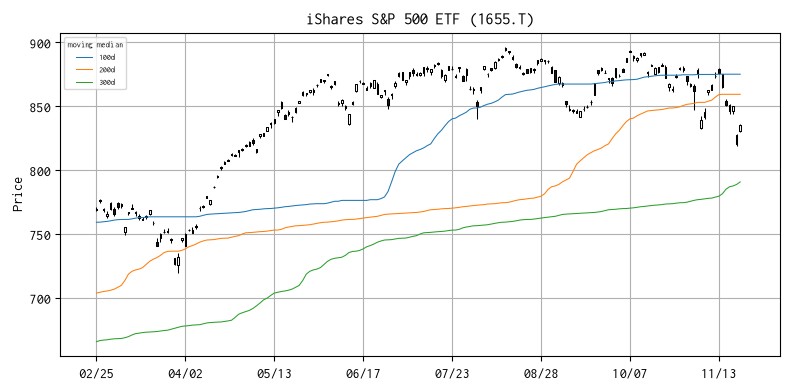

In [5]:
plot_month(symbol1, yticker1, df0, df1)